# Análisis experimental del carrito DQN

Este notebook compara las arquitecturas **Base 64** y **Alternativa 32** bajo dos condiciones de evaluación:

- `fija`: `random_start=False`
- `aleatoria`: `random_start=True`

**Importante:** no se generan datos ficticios. El notebook lee los resultados experimentales desde evaluate.py. La unidad de variación entre entrenamientos es la **semilla**; los episodios de un mismo modelo no deben interpretarse como entrenamientos independientes.




In [1]:
# 1. Librerías
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 110,
})

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)


Pandas: 2.3.3
NumPy: 2.4.6


In [2]:
CSV_PATH = Path("evaluation_results.csv")

if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo: {CSV_PATH.resolve()}. "
        "Coloca evaluation_results.csv en la carpeta del proyecto."
    )

df = pd.read_csv(CSV_PATH)

display(df.head())
print("Archivo utilizado:", CSV_PATH.resolve())
print("Filas:", len(df))


,configuracion,semilla,condicion,episodio,reward,success,collision,steps
0,Base64,42,fija,1,159.610807,1.0,0.0,294.0
1,Base64,42,fija,2,159.610807,1.0,0.0,294.0
2,Base64,42,fija,3,159.610807,1.0,0.0,294.0
3,Base64,42,fija,4,159.610807,1.0,0.0,294.0
4,Base64,42,fija,5,159.610807,1.0,0.0,294.0


Archivo utilizado: D:\SéptimoSemestre\Carrito_DQN_Profesor\evaluation_results.csv
Filas: 120


In [4]:
# 3. Validación y preparación de datos
required = {
    "configuracion", "semilla", "condicion", "episodio",
    "reward", "success", "collision", "steps"
}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Faltan columnas obligatorias: {sorted(missing)}")

df = df.copy()
df["configuracion"] = df["configuracion"].astype(str)
df["condicion"] = df["condicion"].astype(str).str.lower()
for col in ["semilla", "episodio", "reward", "success", "collision", "steps"]:
    df[col] = pd.to_numeric(df[col], errors="raise")

if not set(df["condicion"].unique()).issubset({"fija", "aleatoria"}):
    raise ValueError("La columna 'condicion' solo debe contener 'fija' y/o 'aleatoria'.")

if not set(df["success"].dropna().unique()).issubset({0, 1}):
    raise ValueError("'success' debe codificarse como 1 (éxito) o 0 (fracaso).")
if not set(df["collision"].dropna().unique()).issubset({0, 1}):
    raise ValueError("'collision' debe codificarse como 1 (colisión) o 0 (sin colisión).")

display(df.describe(include="all"))
print("Configuraciones:", sorted(df["configuracion"].unique()))
print("Semillas:", sorted(df["semilla"].unique()))
print("Condiciones:", sorted(df["condicion"].unique()))


,configuracion,semilla,condicion,episodio,reward,success,collision,steps
count,120,120.000000,120,120.000000,120.000000,120.0,120.0,120.000000
unique,2,NaN,2,NaN,NaN,NaN,NaN,NaN
top,Base64,NaN,fija,NaN,NaN,NaN,NaN,NaN
freq,60,NaN,60,NaN,NaN,NaN,NaN,NaN
mean,NaN,388.000000,NaN,5.500000,160.184511,1.0,0.0,300.458333
std,NaN,435.122701,NaN,2.884324,0.552402,0.0,0.0,5.446294
min,NaN,42.000000,NaN,1.000000,159.351807,1.0,0.0,294.000000
25%,NaN,42.000000,NaN,3.000000,159.654133,1.0,0.0,295.000000
50%,NaN,123.000000,NaN,5.500000,160.190316,1.0,0.0,300.000000
75%,NaN,999.000000,NaN,8.000000,160.637128,1.0,0.0,306.000000


Configuraciones: ['Base32', 'Base64']
Semillas: [np.int64(42), np.int64(123), np.int64(999)]
Condiciones: ['aleatoria', 'fija']


## 4. Resumen por modelo, semilla y condición

Primero se resume cada evaluación (configuración + semilla + condición). Después se calcula la media y desviación estándar entre semillas. Esto evita tratar cada episodio como si fuera un entrenamiento independiente.


In [5]:
# Una fila por combinación de configuración, semilla y condición
por_semilla = (
    df.groupby(["configuracion", "semilla", "condicion"], as_index=False)
      .agg(
          episodios=("episodio", "count"),
          exitos=("success", "sum"),
          tasa_exito=("success", "mean"),
          tasa_colision=("collision", "mean"),
          retorno_promedio=("reward", "mean"),
          pasos_promedio=("steps", "mean"),
      )
)

display(por_semilla.round(3))


,configuracion,semilla,condicion,episodios,exitos,tasa_exito,tasa_colision,retorno_promedio,pasos_promedio
0,Base32,42,aleatoria,10,10.0,1.0,0.0,159.791,297.5
1,Base32,42,fija,10,10.0,1.0,0.0,159.654,297.0
2,Base32,123,aleatoria,10,10.0,1.0,0.0,160.895,305.5
3,Base32,123,fija,10,10.0,1.0,0.0,161.084,306.0
4,Base32,999,aleatoria,10,10.0,1.0,0.0,159.698,295.0
5,Base32,999,fija,10,10.0,1.0,0.0,159.777,295.0
6,Base64,42,aleatoria,10,10.0,1.0,0.0,159.502,294.1
7,Base64,42,fija,10,10.0,1.0,0.0,159.611,294.0
8,Base64,123,aleatoria,10,10.0,1.0,0.0,160.509,302.6
9,Base64,123,fija,10,10.0,1.0,0.0,160.398,302.0


In [6]:
# Media y desviación estándar ENTRE SEMILLAS
metricas = [
    "tasa_exito", "tasa_colision", "retorno_promedio", "pasos_promedio"
]

resumen = (
    por_semilla.groupby(["configuracion", "condicion"])[metricas]
    .agg(["mean", "std"])
)

display(resumen.round(3))


tasa_exito      tasa_colision      retorno_promedio  \
                              mean  std          mean  std             mean   
configuracion condicion                                                       
Base32        aleatoria        1.0  0.0           0.0  0.0          160.128   
              fija             1.0  0.0           0.0  0.0          160.172   
Base64        aleatoria        1.0  0.0           0.0  0.0          160.258   
              fija             1.0  0.0           0.0  0.0          160.180   

                               pasos_promedio         
                           std           mean    std  
configuracion condicion                               
Base32        aleatoria  0.666        299.333  5.485  
              fija       0.792        299.333  5.859  
Base64        aleatoria  0.667        301.833  7.380  
              fija       0.498        301.333  7.024

## 5. Gráfica de tasa de éxito

La tasa se expresa como porcentaje. Cada punto/barra resume la media entre semillas; las barras de error muestran ±1 desviación estándar entre semillas.


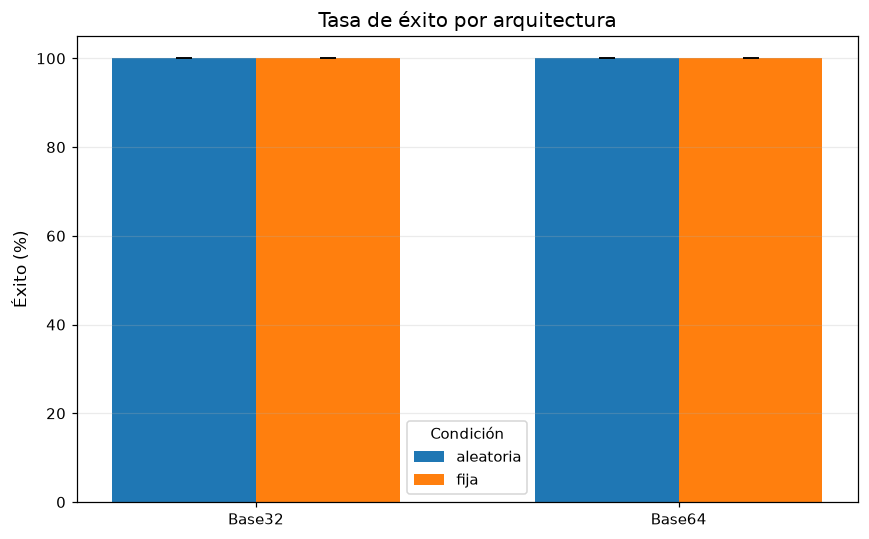

In [7]:
def plot_mean_std(data, metric, title, ylabel, percent=False):
    stats = (
        data.groupby(["configuracion", "condicion"])[metric]
        .agg(["mean", "std"])
        .reset_index()
    )
    configs = list(stats["configuracion"].unique())
    conditions = list(stats["condicion"].unique())
    x = np.arange(len(configs))
    width = 0.34 if len(conditions) > 1 else 0.55

    fig, ax = plt.subplots()
    for i, condition in enumerate(conditions):
        subset = stats[stats["condicion"] == condition].set_index("configuracion").reindex(configs)
        offset = (i - (len(conditions)-1)/2) * width
        means = subset["mean"].to_numpy(dtype=float)
        stds = subset["std"].fillna(0).to_numpy(dtype=float)
        scale = 100 if percent else 1
        ax.bar(x + offset, means * scale, width,
               yerr=stds * scale, capsize=5, label=condition)
    ax.set_xticks(x)
    ax.set_xticklabels(configs)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.legend(title="Condición")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

plot_mean_std(por_semilla, "tasa_exito",
              "Tasa de éxito por arquitectura", "Éxito (%)", percent=True)


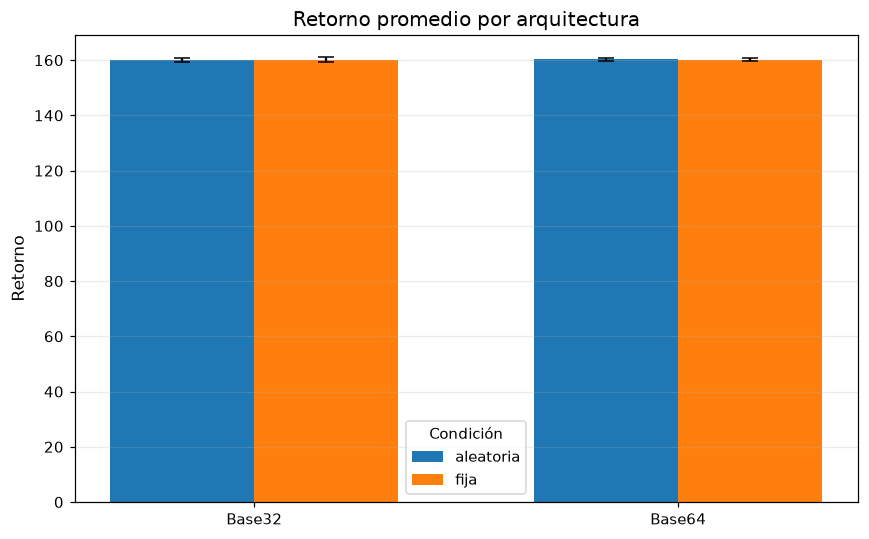

In [8]:
# 6. Retorno promedio
plot_mean_std(por_semilla, "retorno_promedio",
              "Retorno promedio por arquitectura", "Retorno")


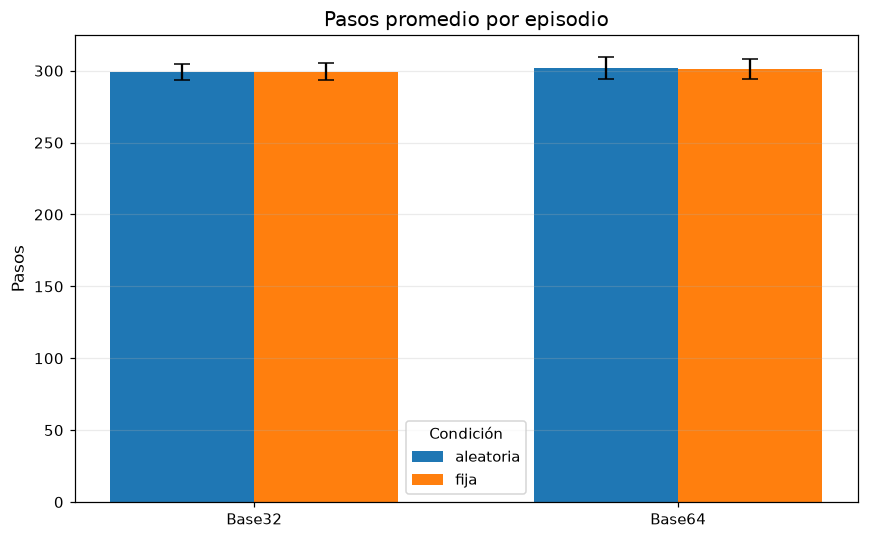

In [9]:
# 7. Pasos promedio
plot_mean_std(por_semilla, "pasos_promedio",
              "Pasos promedio por episodio", "Pasos")


## 8. Distribución de retornos por semilla

Cada punto representa el retorno promedio de una semilla (no un episodio individual). Esto permite visualizar la variabilidad entre entrenamientos.


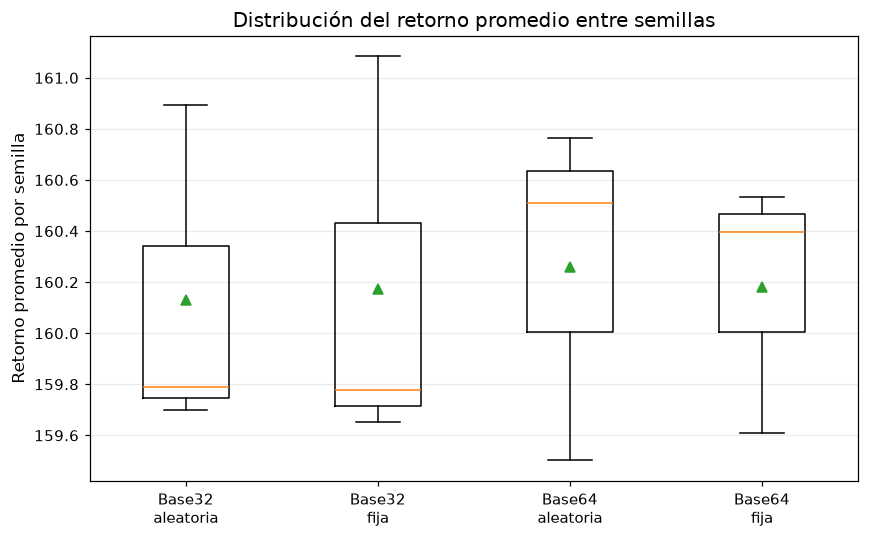

In [12]:
fig, ax = plt.subplots()
labels, values = [], []
for (config, condition), group in por_semilla.groupby(["configuracion", "condicion"]):
    labels.append(f"{config}\n{condition}")
    values.append(group["retorno_promedio"].to_numpy())

if values:
    ax.boxplot(values, tick_labels=labels, showmeans=True)
    ax.set_title("Distribución del retorno promedio entre semillas")
    ax.set_ylabel("Retorno promedio por semilla")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("No hay datos suficientes para generar el diagrama.")


## 9. Comparación de condiciones fijas y aleatorias

Esta gráfica compara el retorno medio de cada arquitectura bajo ambas condiciones. Si todavía no has ejecutado la evaluación aleatoria, aparecerá únicamente la condición fija.


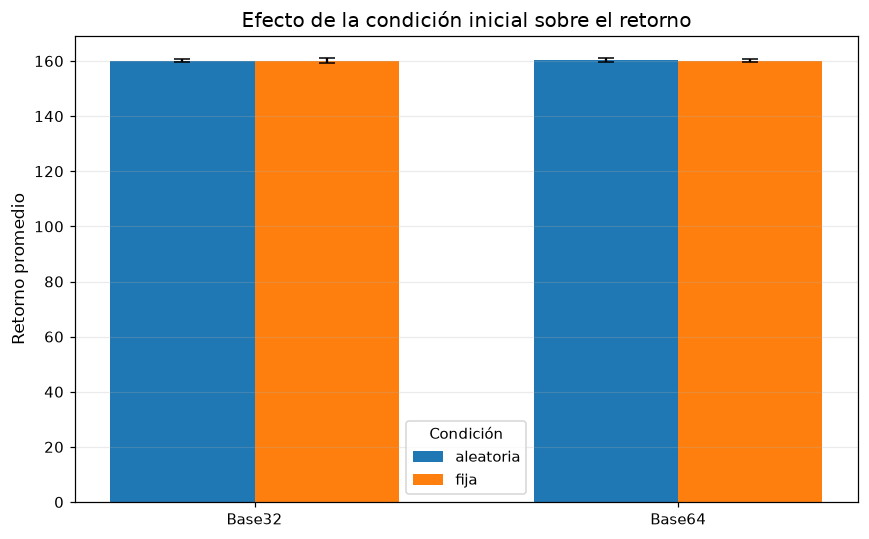

In [13]:
plot_mean_std(por_semilla, "retorno_promedio",
              "Efecto de la condición inicial sobre el retorno",
              "Retorno promedio")


## 10. Exportar tablas y resultados procesados

Los archivos se guardan junto al notebook. La tabla `resumen_por_semilla.csv` conserva cada semilla y condición; `resumen_estadistico.csv` contiene los agregados.


In [14]:
por_semilla.to_csv("resumen_por_semilla.csv", index=False)
resumen.to_csv("resumen_estadistico.csv")
print("Archivos exportados:")
print(Path("resumen_por_semilla.csv").resolve())
print(Path("resumen_estadistico.csv").resolve())


Archivos exportados:
C:\Users\mafer\Downloads\resumen_por_semilla.csv
C:\Users\mafer\Downloads\resumen_estadistico.csv


## 11. Guía para redactar las conclusiones

Completa esta sección después de ejecutar el notebook con tus datos reales:

- **Tasa de éxito:** indica qué arquitectura obtuvo mayor tasa y si la diferencia se mantiene entre semillas.
- **Colisiones:** informa si se observaron colisiones y bajo qué condición.
- **Retorno:** compara medias y variabilidad entre semillas.
- **Pasos:** interpreta si completar el recorrido requirió más o menos pasos; no asumas que menos pasos siempre significa mejor control sin considerar éxito y retorno.
- **Condiciones iniciales:** compara fija y aleatoria solo si ambas evaluaciones están presentes.
- **Limitaciones:** especifica el número de semillas, episodios y el rango de variaciones iniciales evaluado. No generalices más allá de esas condiciones.

**Nota metodológica:** con tres semillas, la desviación estándar entre semillas es descriptiva y la incertidumbre estadística sigue siendo considerable. Reporta el número de semillas junto a los resultados.
